# 10 · The combined method against the published benchmarks

Fine-tuning on the newest data, a reranker that reads label names, an LLM's suggestions and a fine-tuned LLM, weighed
together by the combiner. Notebook 12 shows the published figures being compared with.

## The bar, written on 6 November 2026, before any of these models was trained

**Discipline.** Test scores of earlier models have already been seen, so everything new is chosen on development data.
Which sources go in, and every setting, is fixed from development results. The test sets are then scored once, and that
run is the one reported, whatever it shows.

**To pass on HumSet** (all 15,147 test excerpts, macro F1 per category, one threshold per label chosen on the development
split), the 95% bootstrap interval must lie above HumBERT's printed score in every category: sectors 0.78, pillars 1D
0.70, subpillars 1D 0.54, pillars 2D 0.71, subpillars 2D 0.51. HumBERT's table does not say how it averages, and that is
stated beside the result.

**To pass on MultiEURLEX** (all 5,000 English test laws, chronological split), the 95% bootstrap interval of mean
R-Precision must lie above BERT's printed scores: 48.4 on all labels and 67.7 at level 3.

**To be called "blowing them away"**, the gain must exceed about 5 points, the largest gain found in the papers read: on
MultiEURLEX 5 points of mean R-Precision on all labels, and on HumSet 0.05 of macro F1 averaged over the five categories.

**Also reported, pass or fail:**

- MultiEURLEX with and without newer development laws in training, because that use of development data differs from
  the paper's setup. A pass that needs newer laws is reported as such.
- Each source's own score, what the combiner gains over the best single source, with an interval, and which sources it
  relies on.
- Rare and never-seen label recall on MultiEURLEX against the best single source.
- Cost per 1,000 items, and the training cost.
- Every reduction from a paper: the LLM uses one LoRA-adapted branch rather than DualMLC's two fused branches, on a
  subset of the training data.

These bars do not change after seeing results.


In [1]:
# Pass mark, set before the run: the most KI-FSPrompt's run on the test laws may be expected to cost, if the
# choice below picks it, judged from its development run.
MAX_KI_TEST_COST_USD = 5.0

from collections import Counter

import numpy as np
import pandas as pd
from IPython.display import Image

from tiered_taxonomy import benchmarks as bm
from tiered_taxonomy import experiment as ex
from tiered_taxonomy import figures as fg
from tiered_taxonomy import gpu_jobs as gj
from tiered_taxonomy import new_technique as nt
from tiered_taxonomy import runs
from tiered_taxonomy import signals as sg
from tiered_taxonomy.config import FIGURES, data_root, load_config
from tiered_taxonomy.methods import combined as cb

root = data_root()
config = load_config()
seed = config["seed"]
words = config["text"]["input_words"]
settings = cb.CombinedSettings(per_source=config["combined"]["per_source"], seed=seed)
plan = config["new_technique"]
jobs = ex.load_results("gpu_jobs")
humset = ex.load_humset(root)
eurlex = ex.load_eurlex(root)
results = {}
pd.DataFrame(jobs["runs"]).T[["base", "flavor", "hours"]]

/Users/matthewharris/git/nvidia-autoontology-demo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,base,flavor,hours
classifier_humset,nlp-thedeep/humbert,a10g-small,0.61
classifier_eurlex,nlpaueb/legal-bert-base-uncased,a10g-small,1.03
classifier_eurlex_newer,nlpaueb/legal-bert-base-uncased,a10g-small,1.09
xr_transformer_eurlex,bert-base-uncased,a10g-large,1.88
reranker_humset,BAAI/bge-reranker-v2-m3,a10g-small,3.27
reranker_eurlex_newer,BAAI/bge-reranker-v2-m3,a10g-small,4.0
llm_humset,Qwen/Qwen2.5-7B,a10g-small,1.78
llm_eurlex_newer,Qwen/Qwen2.5-7B,a10g-small,3.37
gliner_humset_failed,fastino/GLiNER2.5-multi-Decide,a10g-small,0.02
gliner_humset,fastino/GLiNER2.5-multi-Decide,a10g-small,2.7


## The sources

Each source ranks every label for every item. The combiner (`src/tiered_taxonomy/methods/combined.py`) weighs them, and adds whether a label's name
is in the text, how often it was seen in training, its tier, and support from its parent and children.

- **Fine-tuned encoder:** HumBERT on HumSet and Legal-BERT on MultiEURLEX, one output per label, as in both papers.
- **Reranker:** bge-reranker-v2-m3 fine-tuned to read a text and a label's name together, over candidates from the other
  sources. The MultiEURLEX job stopped at its four-hour limit, so its rankings are from its first epoch. Its
  training candidates cannot be rebuilt exactly (see `scripts/hf_jobs/prepare_inputs.py`): about 0.2% to 0.5% of
  them differ on a rebuild. Its development and test candidates are rebuilt exactly.
- **Fine-tuned small LLM:** Qwen2.5-7B adapted with LoRA, one output per label. This is one branch of DualMLC
  (arXiv 2609.12915), on a subset of the training data, so it says nothing about the paper's full method.
- **XR-Transformer, Omikuji, embedding classifier, similar documents (kNN) and label search:** from notebooks 08 and 09.
- **KI-FSPrompt:** suggestions from Gemma 3 12B and 27B through DeepInfra on Hugging Face's router, reduced as described
  in notebook 09. MultiEURLEX only: on 9 November 2026 Hugging Face listed Gemma 3 12B as unavailable on both of its
  providers, so it could not be run on HumSet's development excerpts. It is left out of HumSet for that reason, not
  because of any result.

The fine-tuning jobs ran on Hugging Face Jobs; the table above is from their job records.

## Getting the sources

The fine-tuning runs were prepared with `scripts/hf_jobs/prepare_inputs.py` and launched with
`scripts/gpu_jobs.py`. This fetches the rankings they uploaded, dropping the few labels with no place in the
tree, and runs KI-FSPrompt on the MultiEURLEX development laws used below. Saved replies are reused, so a rerun costs nothing.

In [2]:
FETCHED = {
    "classifier_humset": (humset, "humset", "classifier"),
    "reranker_humset": (humset, "humset", "reranker"),
    "llm_humset": (humset, "humset", "llm"),
    "classifier_eurlex": (eurlex, "eurlex", "classifier"),
    "xr_transformer_eurlex": (eurlex, "eurlex", "xr_transformer"),
    "classifier_eurlex_newer": (eurlex, "eurlex_newer", "classifier"),
    "reranker_eurlex_newer": (eurlex, "eurlex_newer", "reranker"),
    "llm_eurlex_newer": (eurlex, "eurlex_newer", "llm"),
}
dropped = {
    run: len(nt.fetch_fine_tuned(root, folder, run, source, data.taxonomy))
    for run, (data, folder, source) in FETCHED.items()
}
print("Labels dropped for having no place in the tree:", dropped)

ki_items = {
    eurlex.name: bm.split_by_date(eurlex.dev)[1][: plan["eurlex"]["fit_items"] + plan["eurlex"]["cut_items"]],
}
results["ki_fsprompt_dev"] = {}
for data in (eurlex,):
    bench = runs.make_bench(data, root, config)
    bench.workers = config["paper_models"]["workers"]
    record = runs.recipe_signals(
        bench, runs.make_recipe_tools(bench), "ki_fsprompt", "dev", ki_items[data.name]
    )
    results["ki_fsprompt_dev"][data.name] = {
        "items": record.items,
        "calls": record.calls,
        "malformed": record.malformed,
        "cost_usd": round(record.cost_usd, 2),
    }
pd.DataFrame(results["ki_fsprompt_dev"])

Labels dropped for having no place in the tree: {'classifier_humset': 0, 'reranker_humset': 0, 'llm_humset': 0, 'classifier_eurlex': 11, 'xr_transformer_eurlex': 13, 'classifier_eurlex_newer': 12, 'reranker_eurlex_newer': 0, 'llm_eurlex_newer': 10}


,eurlex
items,2500.00
calls,7500.00
malformed,106.00
cost_usd,0.97


## Choosing the sources, on development items only

The combiner trains on one part of the development data and is scored on another. Every source is scored alone, the
combiner is scored with every source, and then without each one in turn. A source stays only if removing it costs more
than a fixed margin (0.001 of mean macro F1 on HumSet, 0.1 points of mean R-Precision on MultiEURLEX).

- **HumSet:** a seeded draw of 10,000 development excerpts. The combiner trains on 6,000. Of the other 4,000, half choose
  each label's threshold and half are scored.
- **MultiEURLEX:** the development laws are split in half by date. The earlier half was added to training for the
  models marked "with newer laws". The later half is held out: the combiner trains on its first 2,000 laws and is scored
  on the next 500.
- **MultiEURLEX without newer laws:** the same, using only sources trained on training laws. The combiner itself still
  trains on later development laws, which the paper's models do not.

In [3]:
def show_choice(test_set, choice):
    """Return each source's score alone and what removing it costs the stack, and print the choice."""
    full = nt.headline(test_set, choice["combined"]["all sources"])
    table = pd.DataFrame(
        {
            "alone": {name: nt.headline(test_set, scores) for name, scores in choice["single"].items()},
            "cost of removing it": {
                name: full - nt.headline(test_set, scores)
                for name, scores in choice["combined"].items()
                if name != "all sources"
            },
        }
    ).sort_values("alone", ascending=False)
    table.index = [fg.method_name(name) for name in table.index]
    chosen = nt.headline(test_set, choice["chosen_scores"])
    print(f"Every source: {full:.4f}. Chosen ({', '.join(choice['chosen'])}): {chosen:.4f}.")
    return table.round(4)


def kept(choice):
    return {key: choice[key] for key in ("single", "combined", "chosen", "chosen_scores")}


HUMSET_CANDIDATES = [
    "classifier",
    "xr_transformer",
    "reranker",
    "llm",
    "omikuji",
    "embedding_classifier",
    "knn",
    "label_search",
]
order = np.random.default_rng(seed).permutation(len(humset.dev))
drawn = nt.with_all_tiers(
    [humset.dev[int(i)] for i in order[: plan["humset"]["fit_items"] + plan["humset"]["cut_items"]]]
)
h_fit, h_cut = drawn[: plan["humset"]["fit_items"]], drawn[plan["humset"]["fit_items"] :]
half = len(h_cut) // 2
h_dev = nt.expand_sources(sg.load_sources(root, humset.name, HUMSET_CANDIDATES, "dev"))
h_graph = cb.LabelGraph(humset.taxonomy, [sorted(bm.gold_with_parents(item)) for item in humset.train])
h_choice = nt.development_choice(
    "humset", h_fit, h_cut, h_cut[:half], h_cut[half:], h_dev, h_graph, words, settings, humset.taxonomy
)
results["humset_choice"] = kept(h_choice)
show_choice("humset", h_choice)

Every source: 0.5792. Chosen (classifier, label_search, xr_transformer): 0.5770.


,alone,cost of removing it
Fine-tuned encoder,0.5660,0.0109
XR-Transformer (paper),0.5469,0.0057
Fine-tuned small LLM,0.5448,-0.0023
Omikuji (TF-IDF),0.5053,-0.0001
Embedding classifier,0.4963,0.0003
Similar documents,0.4818,-0.0010
Fine-tuned reranker,0.4736,-0.0011
Label search,0.2278,0.0040


In [4]:
EURLEX_CANDIDATES = [
    "classifier",
    "classifier_train_only",
    "xr_transformer",
    "reranker",
    "llm",
    "omikuji",
    "embedding_classifier",
    "knn",
    "label_search",
    "ki_fsprompt",
]
early, late = bm.split_by_date(eurlex.dev)
late = late[: plan["eurlex"]["fit_items"] + plan["eurlex"]["cut_items"]]
e_fit, e_cut = late[: plan["eurlex"]["fit_items"]], late[plan["eurlex"]["fit_items"] :]
e_dev = nt.eurlex_sources(root, EURLEX_CANDIDATES, "dev", with_newer=True)
newer_graph = cb.LabelGraph(eurlex.taxonomy, [sorted(item.labels) for item in [*eurlex.train, *early]])
e_choice = nt.development_choice(
    "eurlex", e_fit, e_cut, e_fit, e_cut, e_dev, newer_graph, words, settings, eurlex.taxonomy
)
results["eurlex_choice"] = kept(e_choice)
show_choice("eurlex", e_choice)

Every source: 70.5785. Chosen (classifier, knn, label_search, llm, reranker): 70.9654.


,alone,cost of removing it
Fine-tuned encoder,56.0648,0.2802
Fine-tuned small LLM,55.3179,0.3141
"Fine-tuned encoder, no newer laws",54.9926,0.0079
Omikuji (TF-IDF),54.1684,-0.2222
XR-Transformer (paper),53.4501,-0.1937
Embedding classifier,53.1684,-0.1854
Similar documents,50.2740,0.1553
Fine-tuned reranker,49.0677,1.1297
KI-FSPrompt (paper),38.0192,-0.6636
Label search,11.4936,0.1345


In [5]:
TRAIN_ONLY_CANDIDATES = [
    "classifier",
    "xr_transformer",
    "omikuji",
    "embedding_classifier",
    "knn",
    "label_search",
    "ki_fsprompt",
]
t_dev = nt.eurlex_sources(root, TRAIN_ONLY_CANDIDATES, "dev", with_newer=False)
train_graph = cb.LabelGraph(eurlex.taxonomy, [sorted(item.labels) for item in eurlex.train])
t_choice = nt.development_choice(
    "eurlex", e_fit, e_cut, e_fit, e_cut, t_dev, train_graph, words, settings, eurlex.taxonomy
)
results["eurlex_train_only_choice"] = kept(t_choice)
show_choice("eurlex", t_choice)

Every source: 67.7413. Chosen (classifier, embedding_classifier, omikuji, xr_transformer): 67.3707.


,alone,cost of removing it
Fine-tuned encoder,54.9926,1.9244
XR-Transformer (paper),53.4501,0.3694
Omikuji (TF-IDF),52.8770,1.0975
Embedding classifier,52.5504,0.7545
Similar documents,48.8967,-0.3337
KI-FSPrompt (paper),38.0192,-0.2306
Label search,11.4936,-0.6938


## KI-FSPrompt on the test laws, if it was chosen

KI-FSPrompt is an LLM method, so it has rankings only for the development laws above. If the choice includes it, or
picks it as the best single source, it is run once now on all 5,000 test laws, after the choice is fixed. Our run did
not choose it. A rerun may, because Omikuji, one of the candidates, trains from random starting points that cannot
be fixed, and that can change the choice.

In [ ]:
KI = "ki_fsprompt"
wanted = {
    *e_choice["chosen"],
    *t_choice["chosen"],
    nt.best_single("eurlex", e_choice),
    nt.best_single("eurlex", t_choice),
}
results["ki_fsprompt_chosen"] = KI in wanted
if KI in wanted:
    dev_run = results["ki_fsprompt_dev"][eurlex.name]
    expected = dev_run["cost_usd"] / dev_run["items"] * len(eurlex.test)
    if expected > MAX_KI_TEST_COST_USD:
        raise RuntimeError(
            f"KI-FSPrompt on the test laws should cost about ${expected:.2f}, over ${MAX_KI_TEST_COST_USD:.2f}"
        )
    bench = runs.make_bench(eurlex, root, config)
    bench.workers = config["paper_models"]["workers"]
    record = runs.recipe_signals(bench, runs.make_recipe_tools(bench), KI, "test", eurlex.test)
    results["ki_fsprompt_test"] = {
        "items": record.items,
        "calls": record.calls,
        "malformed": record.malformed,
        "cost_usd": round(record.cost_usd, 2),
    }
print("KI-FSPrompt chosen:", results["ki_fsprompt_chosen"], results.get("ki_fsprompt_test", ""))

## The one test run

The sources and settings are now fixed. Each test set is scored once with them, and that run is reported. The combiner
is trained on the same development items as above. On HumSet each label's threshold is chosen on all 4,000 held-out
development excerpts, for the stack and for the best single source alike.

In [6]:
h_test = nt.with_all_tiers(humset.test)
if len(h_test) != 15147:
    raise ValueError(f"expected all 15,147 HumSet test excerpts, found {len(h_test)}")
h_best = nt.best_single("humset", h_choice)
h_names = h_choice["chosen"]
h_test_sources = nt.expand_sources(sg.load_sources(root, humset.name, sorted({*h_names, h_best}), "test"))
h_stack = nt.Stack(h_names, h_fit, h_cut, h_dev, h_test_sources, h_graph, words, settings)
h_final = nt.humset_final(h_stack, h_test, h_best, humset.taxonomy, seed)
sg.save_signal(
    root,
    humset.name,
    "new_technique",
    "test",
    {item.id: ranking for item, ranking in zip(h_test, h_final.pop("rankings"), strict=True)},
)
results["humset"] = {**h_final, "sources": h_names, "best_single_source": h_best}
categories = [*bm.HUMBERT_BEST, "Mean"]
printed = {**bm.HUMBERT_BEST, "Mean": float(np.mean(list(bm.HUMBERT_BEST.values())))}
table = pd.DataFrame(
    {
        "HumBERT, printed": printed,
        f"best single ({fg.method_name(h_best)})": h_final["best_single"],
        "new technique": h_final["scores"],
        "95% low": {name: low for name, (low, _) in h_final["intervals"].items()},
        "95% high": {name: high for name, (_, high) in h_final["intervals"].items()},
        "passes": {**h_final["passes"], "Mean": all(h_final["passes"].values())},
    }
).loc[categories]
point, low, high = h_final["gain_over_best_single"]
print(f"Gain over the best single source: {point:+.3f} mean macro F1 (95% {low:+.3f} to {high:+.3f})")
print("Well ahead of HumBERT (interval above its mean + 0.05):", h_final["well_ahead"])
table.round(3)

Gain over the best single source: +0.013 mean macro F1 (95% +0.010 to +0.016)
Well ahead of HumBERT (interval above its mean + 0.05): False


,"HumBERT, printed",best single (Fine-tuned encoder),new technique,95% low,95% high,passes
Sectors,0.780,0.726,0.742,0.735,0.750,False
Pillars 1D,0.700,0.549,0.553,0.535,0.568,False
Subpillars 1D,0.540,0.434,0.453,0.438,0.464,False
Pillars 2D,0.710,0.633,0.646,0.635,0.656,False
Subpillars 2D,0.510,0.461,0.475,0.463,0.488,False
Mean,0.648,0.561,0.574,0.567,0.579,False


HumBERT's table does not say how it averages. The same predictions, averaged in each usual way:

In [7]:
pd.DataFrame(h_final["other_averages"]).T.round(3)

,macro,weighted,micro,sample
Sectors,0.742,0.758,0.757,0.796
Pillars 1D,0.553,0.609,0.595,0.680
Subpillars 1D,0.453,0.553,0.531,0.592
Pillars 2D,0.646,0.685,0.686,0.728
Subpillars 2D,0.475,0.588,0.584,0.619


In [8]:
e_test = eurlex.test
if len(e_test) != 5000:
    raise ValueError(f"expected all 5,000 MultiEURLEX test laws, found {len(e_test)}")


def eurlex_run(choice, dev_sources, graph, with_newer, counts, name):
    best = nt.best_single("eurlex", choice)
    names = choice["chosen"]
    test_sources = nt.eurlex_sources(root, sorted({*names, best}), "test", with_newer=with_newer)
    stack = nt.Stack(names, e_fit, e_cut, dev_sources, test_sources, graph, words, settings)
    final = nt.eurlex_final(stack, e_test, best, eurlex.taxonomy, counts, seed)
    sg.save_signal(
        root,
        eurlex.name,
        name,
        "test",
        {item.id: ranking for item, ranking in zip(e_test, final.pop("rankings"), strict=True)},
    )
    return {**final, "sources": names, "best_single_source": best}


newer_counts = Counter(label for item in [*eurlex.train, *early] for label in item.labels)
results["eurlex"] = eurlex_run(e_choice, e_dev, newer_graph, True, newer_counts, "new_technique")
results["eurlex_train_only"] = eurlex_run(
    t_choice, t_dev, train_graph, False, eurlex.train_counts, "new_technique_train_only"
)
rows = {"BERT, printed": bm.MULTI_EURLEX_BERT}
for key, label in (("eurlex", "with newer laws"), ("eurlex_train_only", "training laws only")):
    run = results[key]
    rows[f"best single, {label} ({fg.method_name(run['best_single_source'])})"] = run["best_single"]
    rows[f"new technique, {label}"] = run["scores"]
    rows[f"  95% interval, {label}"] = {
        level: f"{low:.1f} to {high:.1f}" for level, (low, high) in run["intervals"].items()
    }
    rows[f"  gain over best single, {label}"] = {
        level: f"{p:+.1f} ({lo:+.1f} to {hi:+.1f})"
        for level, (p, lo, hi) in run["gain_over_best_single"].items()
    }
    rows[f"  passes, {label}"] = run["passes"]
    rows[f"  well ahead (interval above BERT + 5), {label}"] = run["well_ahead"]
pd.DataFrame(rows).T.rename(columns={"all": "all labels", "level_3": "level 3"})

,all labels,level 3
"BERT, printed",48.4,67.7
"best single, with newer laws (Fine-tuned encoder)",52.933549,70.903725
"new technique, with newer laws",62.417752,74.489808
"95% interval, with newer laws",61.8 to 63.0,74.0 to 75.1
"gain over best single, with newer laws",+9.5 (+9.1 to +9.9),+3.6 (+3.2 to +3.9)
"passes, with newer laws",True,True
"well ahead (interval above BERT + 5), with newer laws",True,True
"best single, training laws only (Fine-tuned encoder)",50.02264,67.945075
"new technique, training laws only",60.037853,72.897517
"95% interval, training laws only",59.3 to 60.7,72.3 to 73.6


## Rare and never-seen labels on MultiEURLEX

Recall within each law's top R labels, where R is its number of gold labels, which is what R-Precision scores. "Seen"
counts the laws each stack trained on.

In [9]:
panels = {}
for key, suffix in (("eurlex", ""), ("eurlex_train_only", "_train_only")):
    for method, bands in results[key]["rarity"].items():
        name = (
            f"new_technique{suffix}"
            if method == "new_technique"
            else ("classifier_train_only" if suffix and method == "classifier" else method)
        )
        panels[name] = {band: value["recall"] for band, value in bands.items()}
path = fg.rarity_bars(
    panels,
    "Recall by how often a label appeared in training",
    "MultiEURLEX, all 5,000 test laws, top R labels",
    FIGURES / "10_rarity.png",
)
pd.DataFrame(
    {
        f"{key}: {fg.method_name(name)}": {
            band: f"{value['recall']:.0%} of {value['gold_labels']}" for band, value in bands.items()
        }
        for key in ("eurlex", "eurlex_train_only")
        for name, bands in results[key]["rarity"].items()
    }
)

,eurlex: New technique,eurlex: Fine-tuned encoder,eurlex_train_only: New technique,eurlex_train_only: Fine-tuned encoder
common,64% of 29698,55% of 29698,62% of 29450,52% of 29450
rare,14% of 890,8% of 890,9% of 1034,6% of 1034
unseen,1% of 518,0% of 518,0% of 622,0% of 622


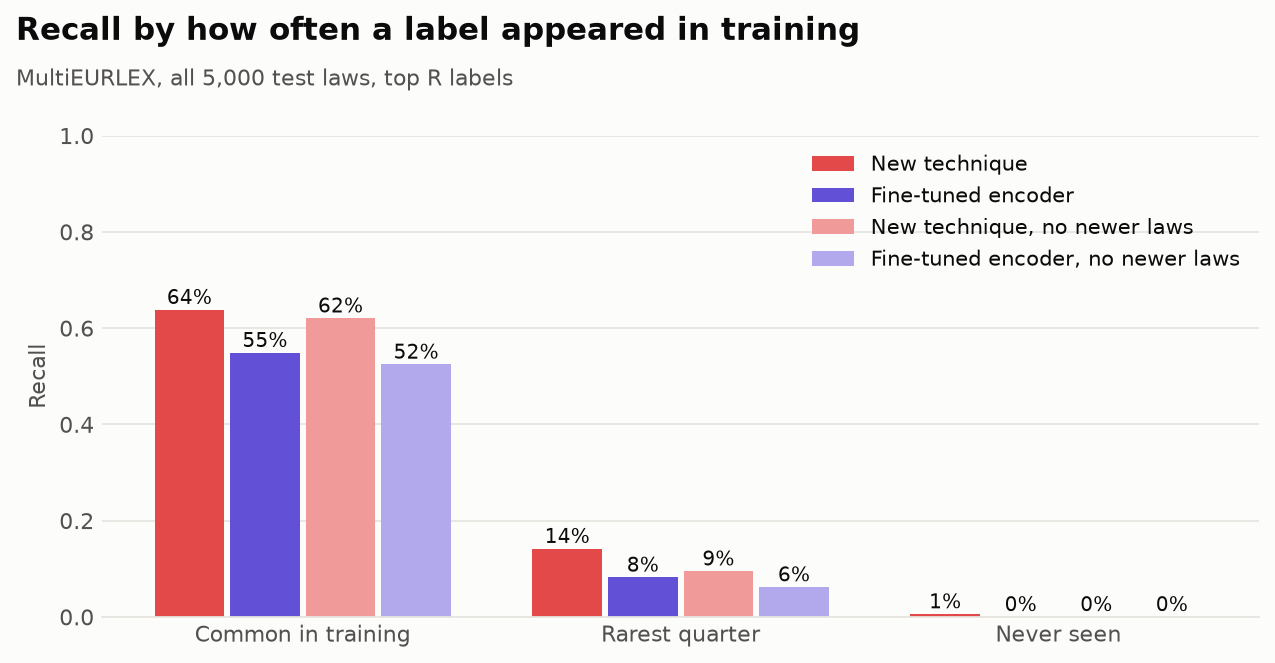

In [10]:
Image(str(path), width=800)

## What the combiner relies on

How much its ranking of candidates on the held-out development items falls when one signal is shuffled, measured by
average precision. The ten largest per stack.

In [11]:
importance = pd.DataFrame(
    {key: results[key]["importance"] for key in ("humset", "eurlex", "eurlex_train_only")}
)
pd.concat(
    [
        importance[key]
        .sort_values(ascending=False)
        .head(10)
        .round(4)
        .reset_index()
        .set_axis(["signal", "drop"], axis=1)
        for key in importance
    ],
    axis=1,
    keys=importance.columns,
)

humset                      eurlex          \
                 signal    drop              signal    drop   
0      classifier_score  0.5745    classifier_score  0.1987   
1  xr_transformer_score  0.0602  log_training_count  0.1136   
2    log_training_count  0.0027        parent_score  0.0878   
3         co_occurrence  0.0016      reranker_score  0.0658   
4          parent_score  0.0001           llm_score  0.0560   
5                  tier  0.0001       co_occurrence  0.0515   
6          name_in_text  0.0000    sources_agreeing  0.0370   
7    label_search_score  0.0000         child_score  0.0293   
8      classifier_found  0.0000                tier  0.0114   
9    label_search_found  0.0000  label_search_score  0.0080   

            eurlex_train_only          
                       signal    drop  
0            classifier_score  0.2924  
1          log_training_count  0.1078  
2                parent_score  0.0598  
3        xr_transformer_score  0.0342  
4               co_occurrence  0.0306  
5                 child_score  0.0286  
6            sources_agreeing  0.0178  
7  embedding_classifier_score  0.0161  
8               omikuji_score  0.0123  
9                        tier  0.0086

## What it cost

Training cost is GPU time on Hugging Face Jobs, from the job records, for the runs each stack uses. Those jobs also
produced the development and test rankings. The other sources ran on a laptop CPU.

In [12]:
RUNS = {
    "humset": {"classifier": "classifier_humset", "reranker": "reranker_humset", "llm": "llm_humset"},
    "eurlex": {
        "classifier": "classifier_eurlex_newer",
        "classifier_train_only": "classifier_eurlex",
        "xr_transformer": "xr_transformer_eurlex",
        "reranker": "reranker_eurlex_newer",
        "llm": "llm_eurlex_newer",
    },
    "eurlex_train_only": {"classifier": "classifier_eurlex", "xr_transformer": "xr_transformer_eurlex"},
}
# If KI-FSPrompt was chosen, its LLM calls on the test laws are in results["ki_fsprompt_test"]; these are GPU costs.


def job_cost(run):
    return gj.run_cost(jobs, run)


costs = {
    key: {
        source: round(job_cost(RUNS[key][source]), 2)
        for source in results[key]["sources"]
        if source in RUNS[key]
    }
    for key in RUNS
}
results["training_cost_usd"] = {key: round(sum(value.values()), 2) for key, value in costs.items()}
results["all_jobs_cost_usd"] = round(sum(job_cost(run) for run in jobs["runs"]), 2)
print("All fine-tuning jobs, used or not: $", results["all_jobs_cost_usd"])
pd.DataFrame(costs).astype(object).fillna("").T.assign(total=pd.Series(results["training_cost_usd"]))

All fine-tuning jobs, used or not: $ 23.15


,classifier,llm,reranker,xr_transformer,total
humset,0.61,,,,0.61
eurlex,1.09,3.37,4.0,,8.46
eurlex_train_only,1.03,,,2.82,3.85


## Charts

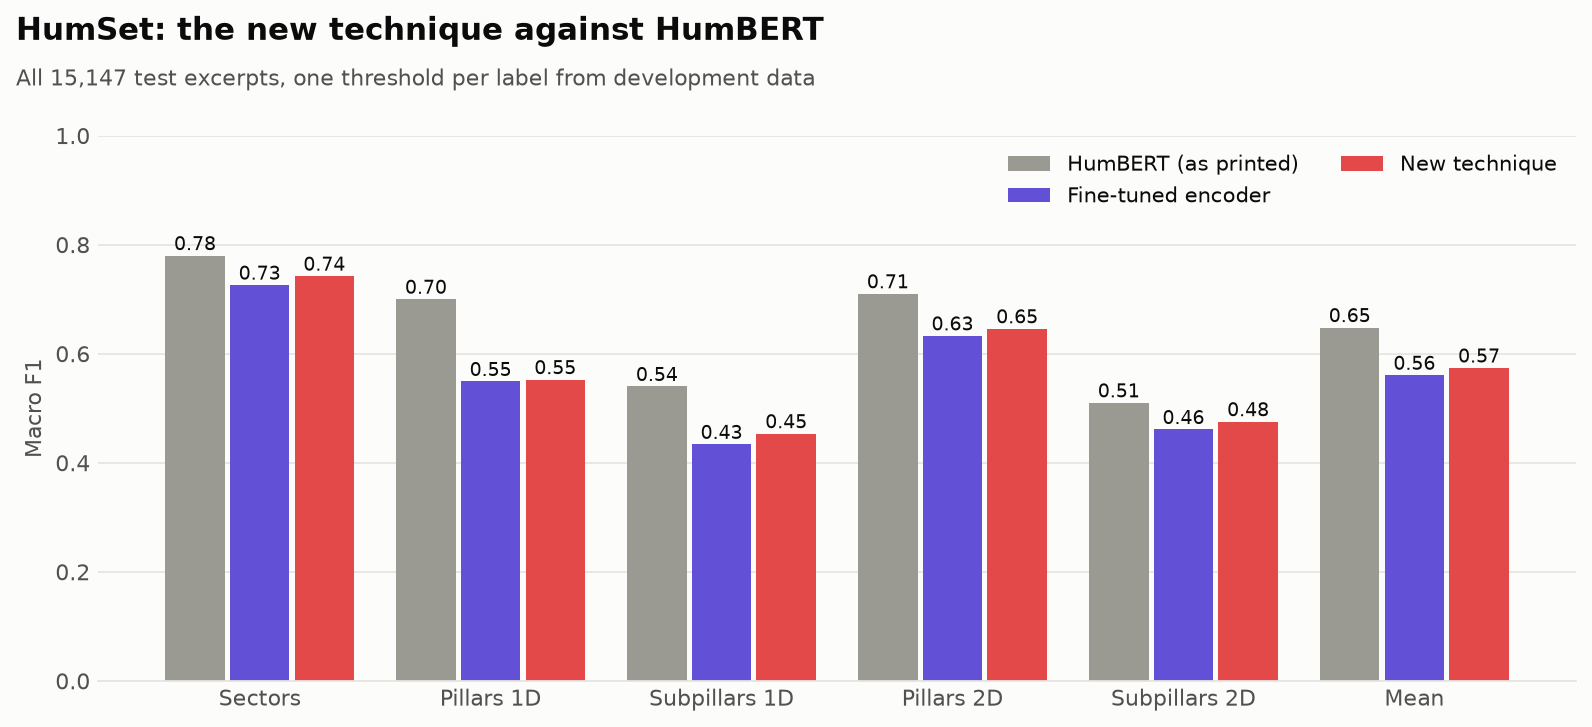

In [13]:
series = {
    "humbert_printed": printed,
    h_best: results["humset"]["best_single"],
    "new_technique": results["humset"]["scores"],
}
path = fg.category_bars(
    {name: {category: values[category] for category in categories} for name, values in series.items()},
    "Macro F1",
    "HumSet: the new technique against HumBERT",
    "All 15,147 test excerpts, one threshold per label from development data",
    FIGURES / "10_humset.png",
)
Image(str(path), width=900)

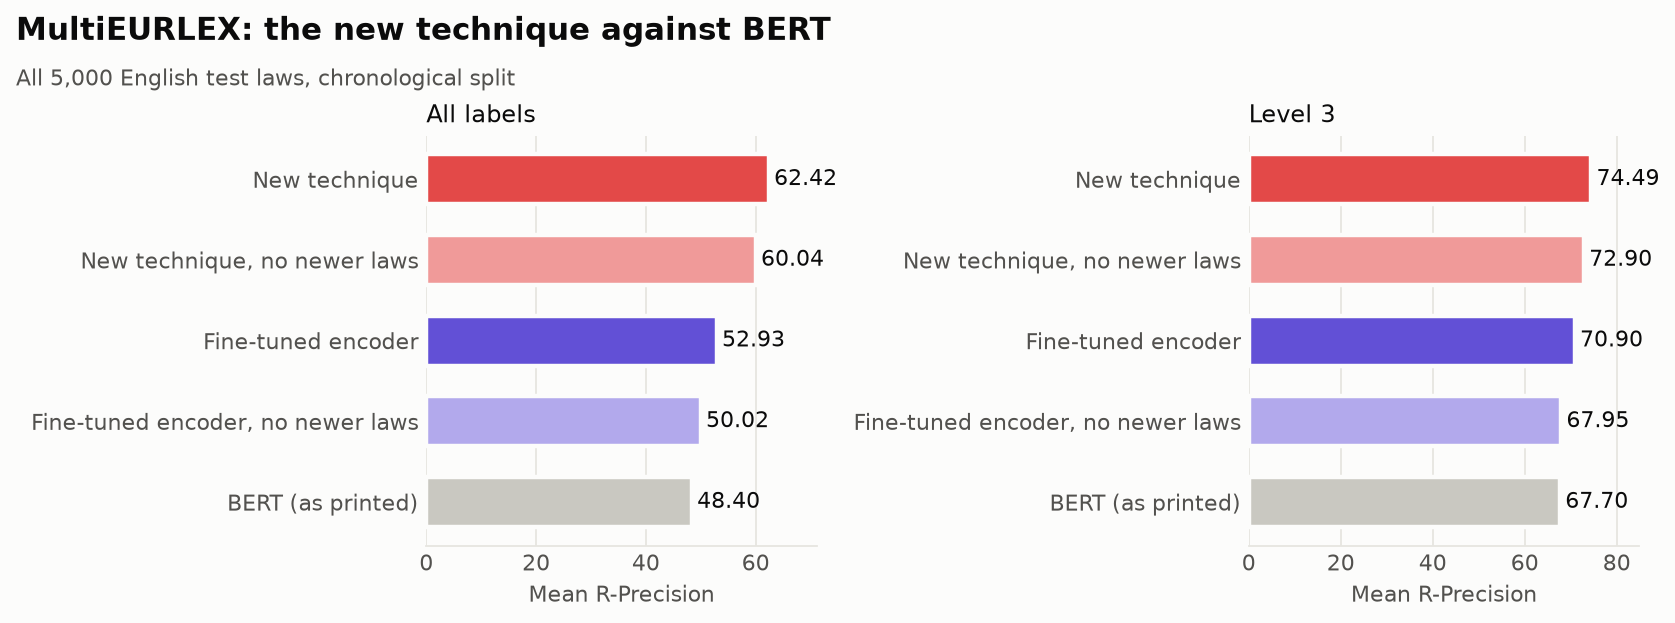

In [14]:
def eurlex_panel(level):
    return {
        "bert_printed": bm.MULTI_EURLEX_BERT[level],
        results["eurlex"]["best_single_source"]: results["eurlex"]["best_single"][level],
        "classifier_train_only": results["eurlex_train_only"]["best_single"][level],
        "new_technique": results["eurlex"]["scores"][level],
        "new_technique_train_only": results["eurlex_train_only"]["scores"][level],
    }


if results["eurlex_train_only"]["best_single_source"] != "classifier":
    raise ValueError("the chart labels the best single source without newer laws as the fine-tuned encoder")
path = fg.method_bars(
    {"All labels": eurlex_panel("all"), "Level 3": eurlex_panel("level_3")},
    "Mean R-Precision",
    "MultiEURLEX: the new technique against BERT",
    "All 5,000 English test laws, chronological split",
    FIGURES / "10_eurlex.png",
)
Image(str(path), width=900)

In [15]:
ex.save_results("10_combined_method", results)
print("saved")

saved
